# Linear regression: weight from height

In [2]:
import numpy as np
import pandas as pd

from scripts.lin_regression_viz import plot_data, plot_init, plot_prediction, plot_training

## Data

saved: C:\Users\Admin\Documents\Study\Projects\eng-regression\outputs\lin_regression_data.png


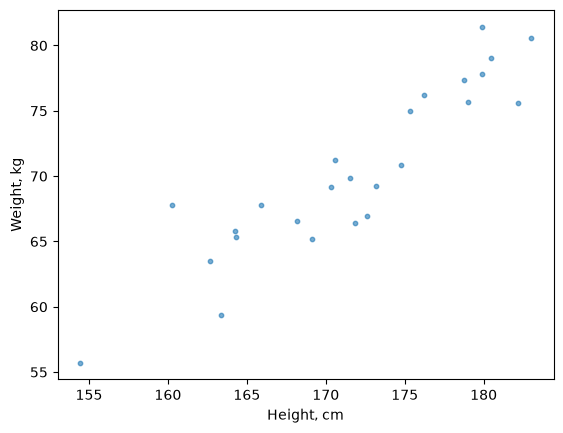

In [3]:
rng = np.random.default_rng(42)
n = 25

height = rng.normal(172, 9, n)
weight = -85 + 0.9 * height + rng.normal(0, 4, n)

df = pd.DataFrame({"height": height, "weight": weight})

plot_data(height, weight)

## Random initialization

In [4]:
X = df["height"].to_numpy()
Y = df["weight"].to_numpy()

mx, sx = X.mean(), X.std()
my, sy = Y.mean(), Y.std()
Xn, Yn = (X - mx) / sx, (Y - my) / sy


def to_original(w_n, b_n):
    w = w_n * sy / sx
    return w, my + sy * b_n - w * mx


def mse_r2(w, b):
    pred = w * X + b
    mse = np.mean((Y - pred) ** 2)
    r2 = 1 - np.sum((Y - pred) ** 2) / np.sum((Y - Y.mean()) ** 2)
    return mse, r2


init_rng = np.random.default_rng(3)
w_n0, b_n0 = init_rng.normal(0, 1, 2)
w_n0 = -abs(w_n0)
w0, b0 = to_original(w_n0, b_n0)
mse0, r2_0 = mse_r2(w0, b0)

plot_init(X, Y, w0, b0, mse0, r2_0).show()

saved: C:\Users\Admin\Documents\Study\Projects\eng-regression\outputs\lin_regression_init.html
PNG export skipped (RuntimeError). To enable it run: uv add kaleido


## Training

In [5]:
lr, epochs = 0.03, 100
w_n, b_n = w_n0, b_n0
hist = {"epoch": [], "w": [], "b": [], "mse": [], "r2": []}


def log(ep, w_n, b_n):
    w, b = to_original(w_n, b_n)
    mse, r2 = mse_r2(w, b)
    for k, v in zip(hist, (ep, w, b, mse, r2), strict=True):
        hist[k].append(v)


log(0, w_n, b_n)
for ep in range(1, epochs + 1):
    err = w_n * Xn + b_n - Yn
    w_n -= lr * 2 * np.mean(err * Xn)
    b_n -= lr * 2 * np.mean(err)
    log(ep, w_n, b_n)

hist = {k: np.array(v) for k, v in hist.items()}
w_gd, b_gd = hist["w"][-1], hist["b"][-1]
print(
    f"GD result after {epochs} epochs: w={w_gd:.4f}, b={b_gd:.3f}, "
    f"MSE={hist['mse'][-1]:.3f}, R2={hist['r2'][-1]:.4f}"
)

GD result after 100 epochs: w=0.7952, b=-66.173, MSE=6.859, R2=0.8338


## Training animation

In [6]:
plot_training(X, Y, hist).show()

saved: C:\Users\Admin\Documents\Study\Projects\eng-regression\outputs\lin_regression_training.html
GIF export skipped (RuntimeError). To enable it run: uv add kaleido


## Prediction

In [7]:
new_height = 180
pred_weight = w_gd * new_height + b_gd

plot_prediction(X, Y, w_gd, b_gd, new_height).show()  # type: ignore
print(f"Height {new_height} cm -> predicted weight {pred_weight:.1f} kg")

saved: C:\Users\Admin\Documents\Study\Projects\eng-regression\outputs\lin_regression_prediction.html
PNG export skipped (RuntimeError). To enable it run: uv add kaleido


Height 180 cm -> predicted weight 77.0 kg
